# Lab 1 Report: 
## Hello PyTorch: Fit Your First Model

### Name: Isaac Margulies

### Lab Overview (3 hours)

This lab accompanies the lecture **Machine Learning & Neural Networks: Least Squares, Evolved**. You will prepare a dataset, split it, and then fit your first neural network in PyTorch by minimizing the Mean Squared Error (least squares) with gradient descent.

| Part | Topic | Time |
|---|---|---|
| Setup | Import libraries | ~10 min |
| Part 1 | Scaling Data with Standard Scaling (CMS calorimeter dataset) | ~50 min |
| Part 2 | Data Splitting and the Iris Dataset | ~50 min |
| Part 3 | Iris Classification using Regression (your first PyTorch model) | ~50 min |
| Bonus | Optional challenges for advanced students | optional |

**How to complete this lab**
* Run the cells from top to bottom (select a cell and press `Shift + Enter`).
* Look for the comment **`# Write your codes`**. Replace it with your code. Each prompt comes with a **Hint** that shows the code you need.
* Cells without `# Write your codes` are already complete. Just run them.
* Each part uses results from the part before it, so do not skip cells.

## Setup (~10 min)

In [1]:
# Import necessary libraries

%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

In [2]:
from IPython.display import Image # For displaying images in colab jupyter cell

---
# Part 1: Scaling Data with Standard Scaling (~50 min)

| Task | Description | Time |
|---|---|---|
| 1.1 | Load the CMS calorimeter dataset | ~10 min |
| 1.2 | Extract the x, y, z, eta, phi and energy columns | ~10 min |
| 1.3 | Write the `scale_data()` function | ~20 min |
| 1.4 | Plot the scaled data | ~10 min |

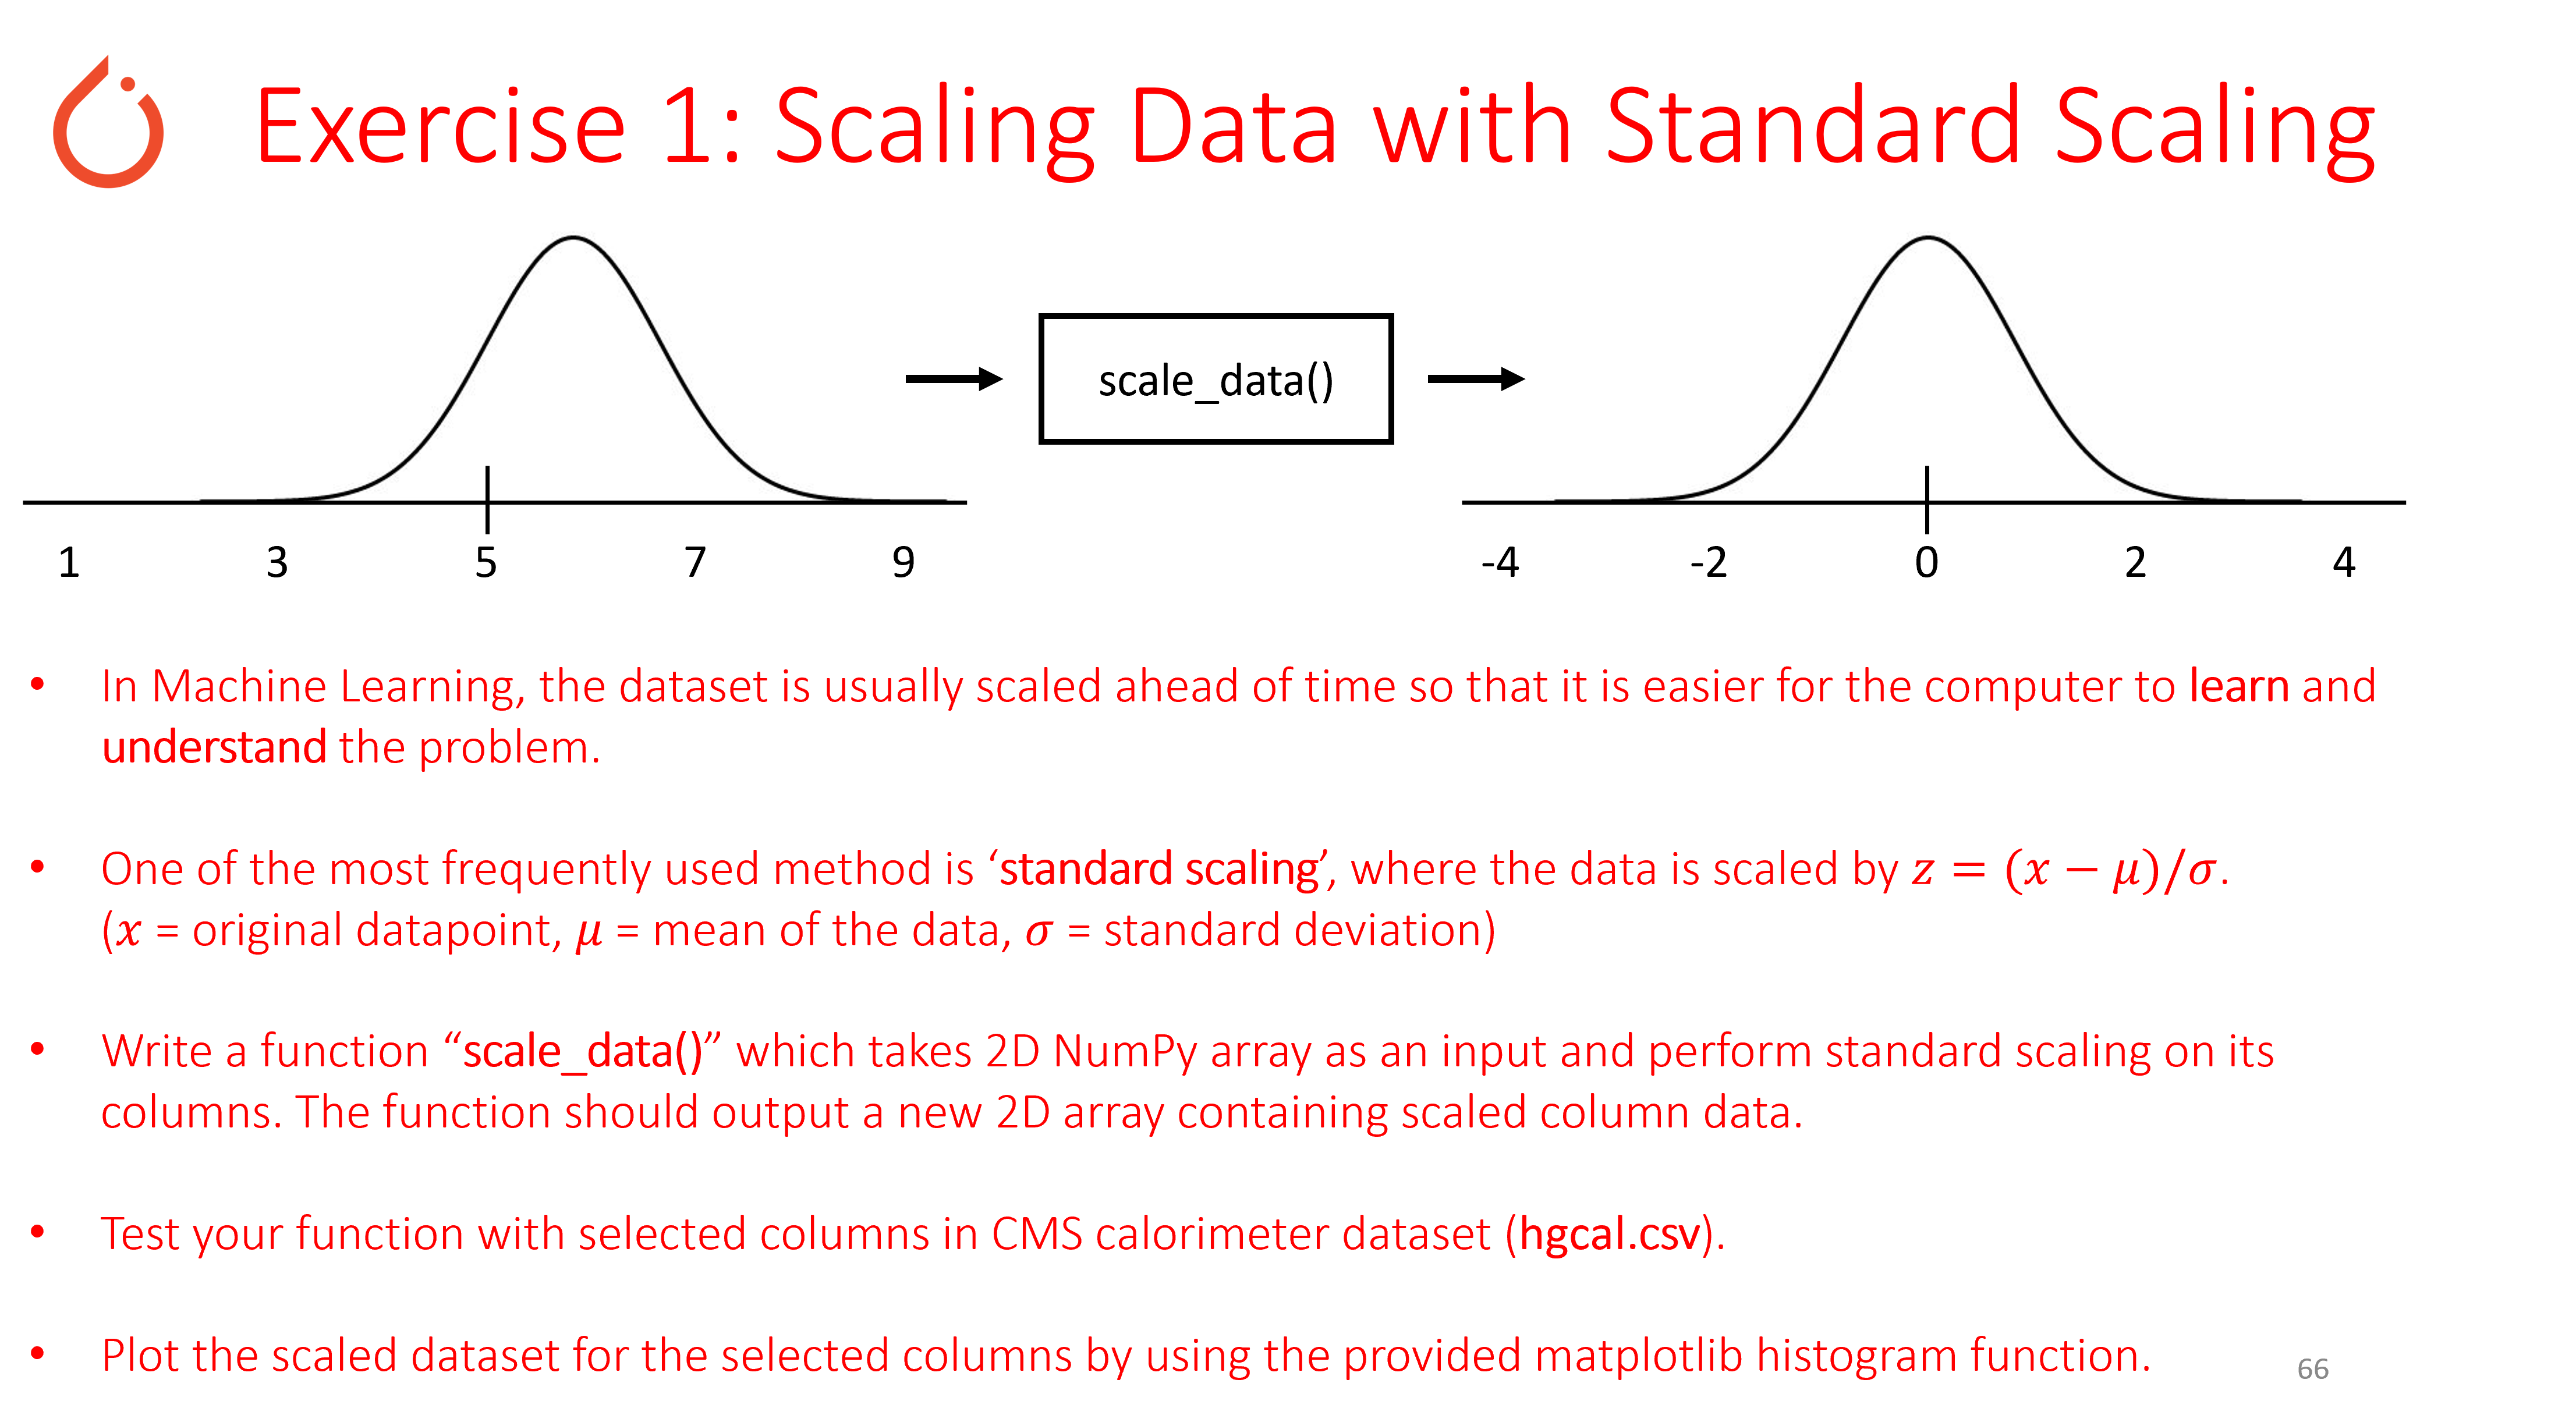

In [3]:
Image('lab1_exercise1.png', width = 1000)

## Task 1.1: Load Data

In [4]:
# Load the dataset (.csv) using pandas package

CMS_calori_dataset = pd.read_csv('hgcal.csv')

# .head directive on the panda dataframe displays the first n-rows

CMS_calori_dataset.head(n = 10)

,Unnamed: 0,x,y,z,eta,phi,energy,trackId
0,0,179.50383,-23.632137,-7.878280,-0.0435,-0.130900,0.200126,462412
1,1,-143.63881,110.217940,-72.706795,-0.3915,2.487094,2.734594,493395
2,2,179.50383,-23.632120,-146.429610,-0.7395,-0.130900,0.423910,1
3,3,-172.67310,54.443620,-238.065340,-1.0875,2.836160,0.713950,493640
4,4,-180.88046,7.897389,-238.065340,-1.0875,3.097959,0.000000,495225
5,5,-180.88045,-7.897438,-238.065340,-1.0875,-3.097959,0.034491,495225
6,6,-152.69838,-97.279590,-265.020540,-1.1745,-2.574361,0.580138,460126
7,7,-23.63213,179.503810,-325.172060,-1.3485,1.701696,0.411487,465028
8,8,-152.69835,97.279594,89.977780,0.4785,2.574361,0.183141,1383
9,9,-176.76110,39.187016,107.930240,0.5655,2.923426,0.337551,4421


In [5]:
# Convert the panda dataframe into numpy 2D array

CMS_calori_dataset_np = CMS_calori_dataset.to_numpy()

# The converted numpy array has the dimension of 420 (rows) x 8 (columns)

print(CMS_calori_dataset_np.shape)

(420, 8)


## Task 1.2: Extract Columns

In [6]:
# Extract only x, y, z, eta, phi and energy columns from the dataset and stack them along column direction
# Name this new 2D array CMS_calori_dataset_np_sub. 
# The array should have dimension 420 (rows) x 6 (columns)

# The columns of CMS_calori_dataset_np are numbered like this:
#   0 = (row number)   1 = x   2 = y   3 = z   4 = eta   5 = phi   6 = energy   7 = trackId
# CMS_calori_dataset_np[:, 1] means "all rows, column 1"

x      = CMS_calori_dataset_np[:, 1]
y      = CMS_calori_dataset_np[:, 2]
z      = CMS_calori_dataset_np[:, 3]
eta    = CMS_calori_dataset_np[:, 4]
phi    = CMS_calori_dataset_np[:, 5]
energy = CMS_calori_dataset_np[:, 6]

# Stack the six columns side by side (already done for you)
CMS_calori_dataset_np_sub = np.stack([x, y, z, eta, phi, energy], axis = 1)

print(CMS_calori_dataset_np_sub.shape)   # Should print (420, 6)

(420, 6)


## Task 1.3: Create the Scaling Function

In [7]:
# Create the scaling function
# Standard scaling: z = (x - mu) / sigma, applied to every column

def scale_data(arr):
    
    # Step 1: mean of each column
    mu = np.mean(arr, axis = 0)
    
    # Step 2: standard deviation of each column
    sigma = np.std(arr, axis = 0)
    
    # Step 3: apply the formula z = (x - mu) / sigma. This is the Z-score of each piece of data.
    scaled_data = (arr - mu) / sigma
    
    return scaled_data

In [8]:
# Test the function with CMS_calori_dataset_np_sub

CMS_calori_dataset_np_sub_scaled = scale_data(CMS_calori_dataset_np_sub)

# Check: after scaling, every column should have mean = 0 and standard deviation = 1

print('Mean of each column:', np.round(CMS_calori_dataset_np_sub_scaled.mean(axis = 0), 3))
print('Std of each column: ', np.round(CMS_calori_dataset_np_sub_scaled.std(axis = 0), 3))

Mean of each column: [ 0. -0.  0.  0. -0.  0.]
Std of each column:  [1. 1. 1. 1. 1. 1.]


## Task 1.4: Plot the Scaled Data

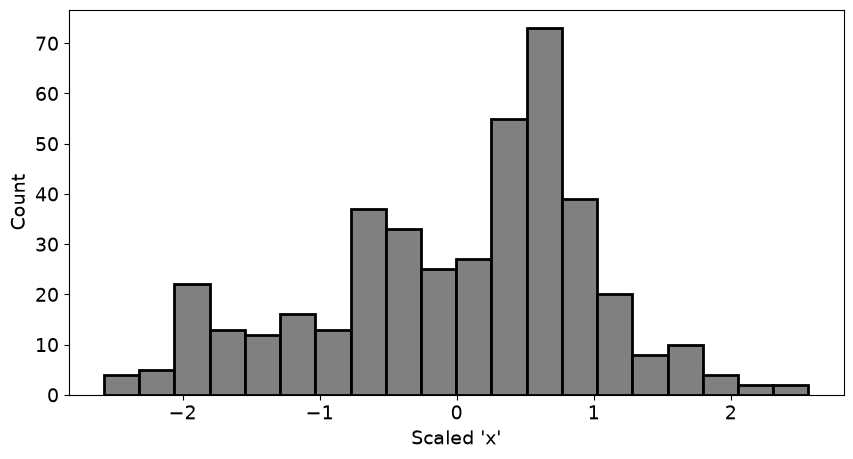

In [9]:
# Confirm the data is scaled for 'x' column. We can see the mean is at zero, and the spread seems reasonable for a standard deviation of 1.

plt.figure(figsize = (10, 5))

plt.hist(CMS_calori_dataset_np_sub_scaled[:, 0], bins = 20, facecolor = 'grey', edgecolor = 'black', linewidth = 2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Scaled 'x'", fontsize = 14)
plt.ylabel('Count', fontsize = 14)

plt.show()

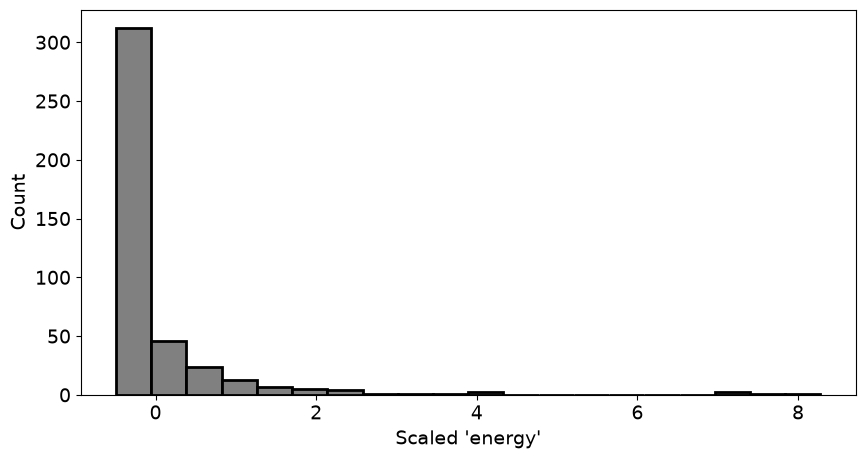

In [10]:
# Confirm the data is scaled for 'energy' column

plt.figure(figsize = (10, 5))

plt.hist(CMS_calori_dataset_np_sub_scaled[:, 5], bins = 20, facecolor = 'grey', edgecolor = 'black', linewidth = 2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Scaled 'energy'", fontsize = 14)
plt.ylabel('Count', fontsize = 14)

plt.show()

### Expected histogram outputs - Feel free to style your plot differently

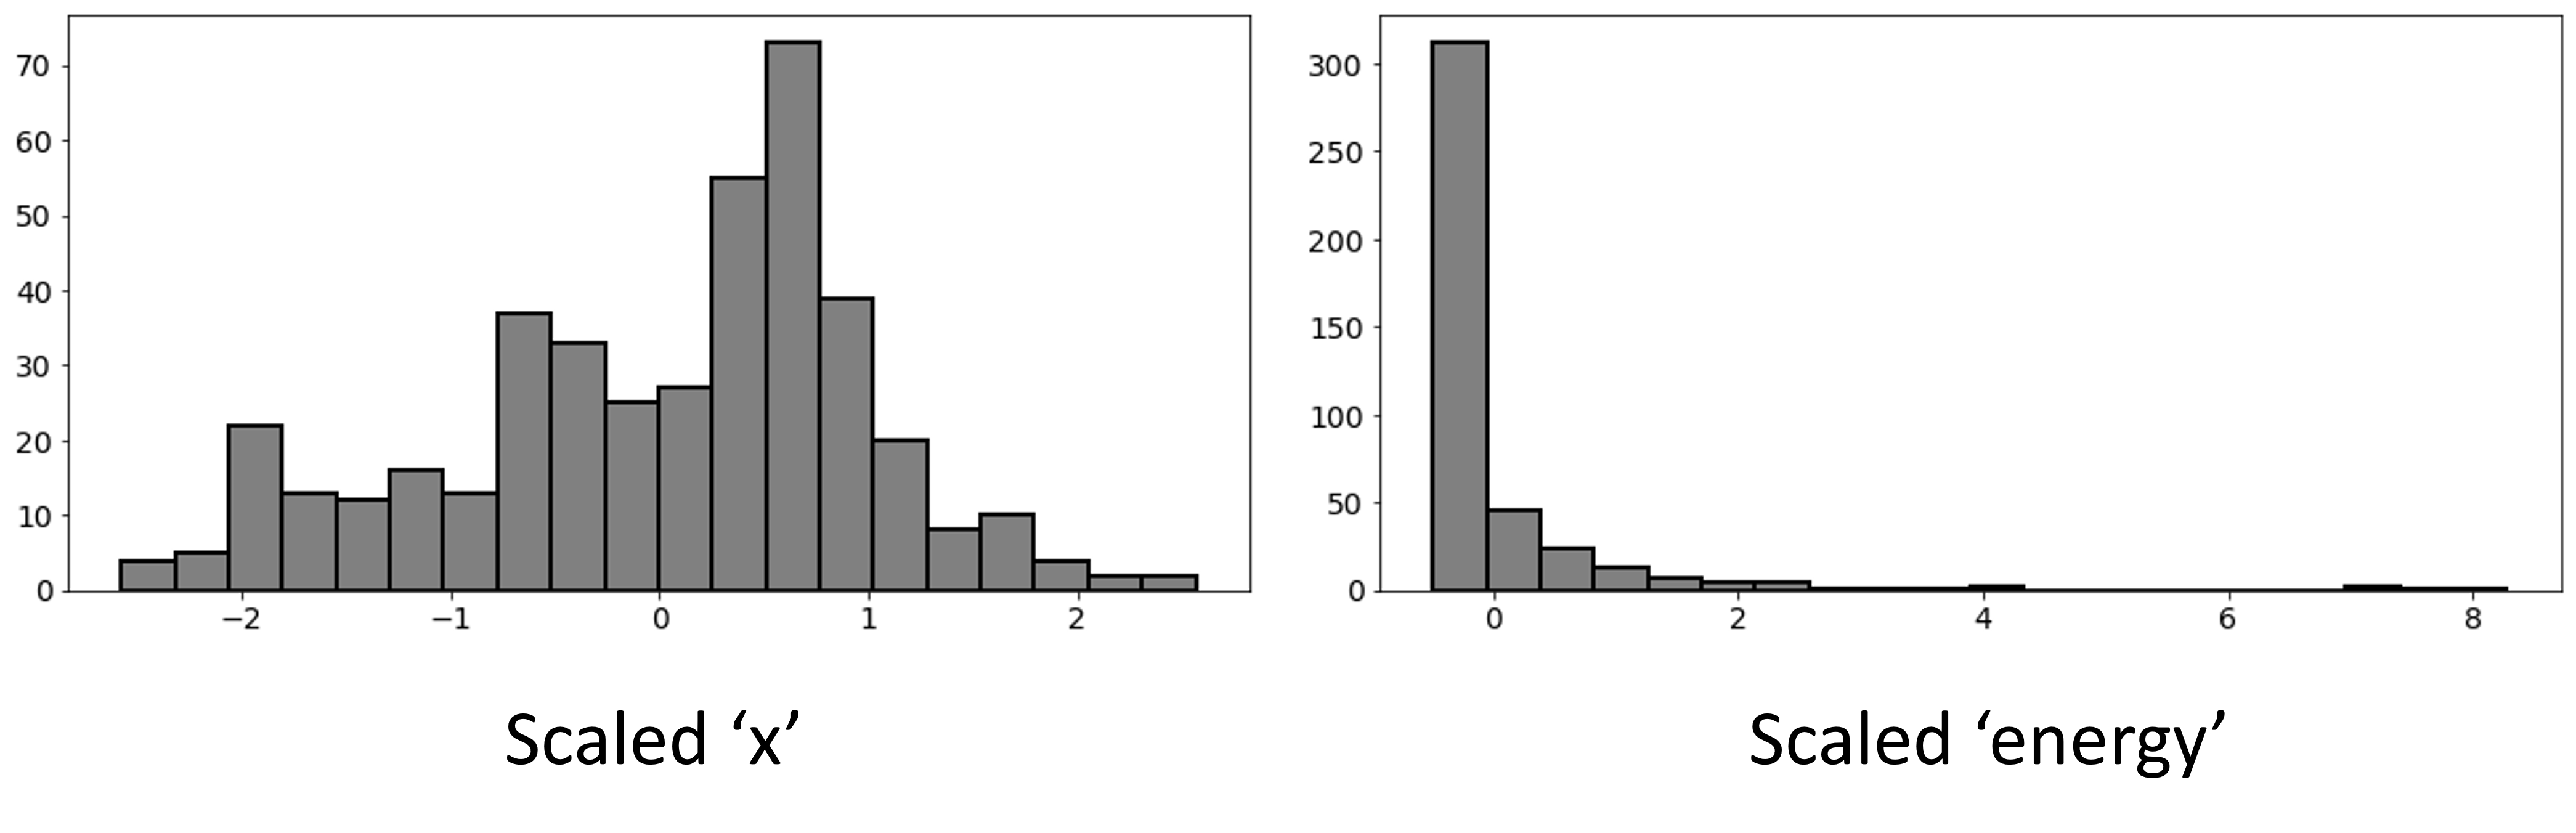

In [11]:
Image('lab1_e1_expected_outputs.png', width = 1000)

---
# Part 2: Data Splitting and the Iris Dataset (~50 min)

| Task | Description | Time |
|---|---|---|
| 2.1 | Write the `split_data()` function | ~20 min |
| 2.2 | Test the function and check the shapes | ~10 min |
| 2.3 | Load and visualize the Iris dataset | ~10 min |
| 2.4 | Scale the Iris features with your `scale_data()` from Part 1 | ~10 min |

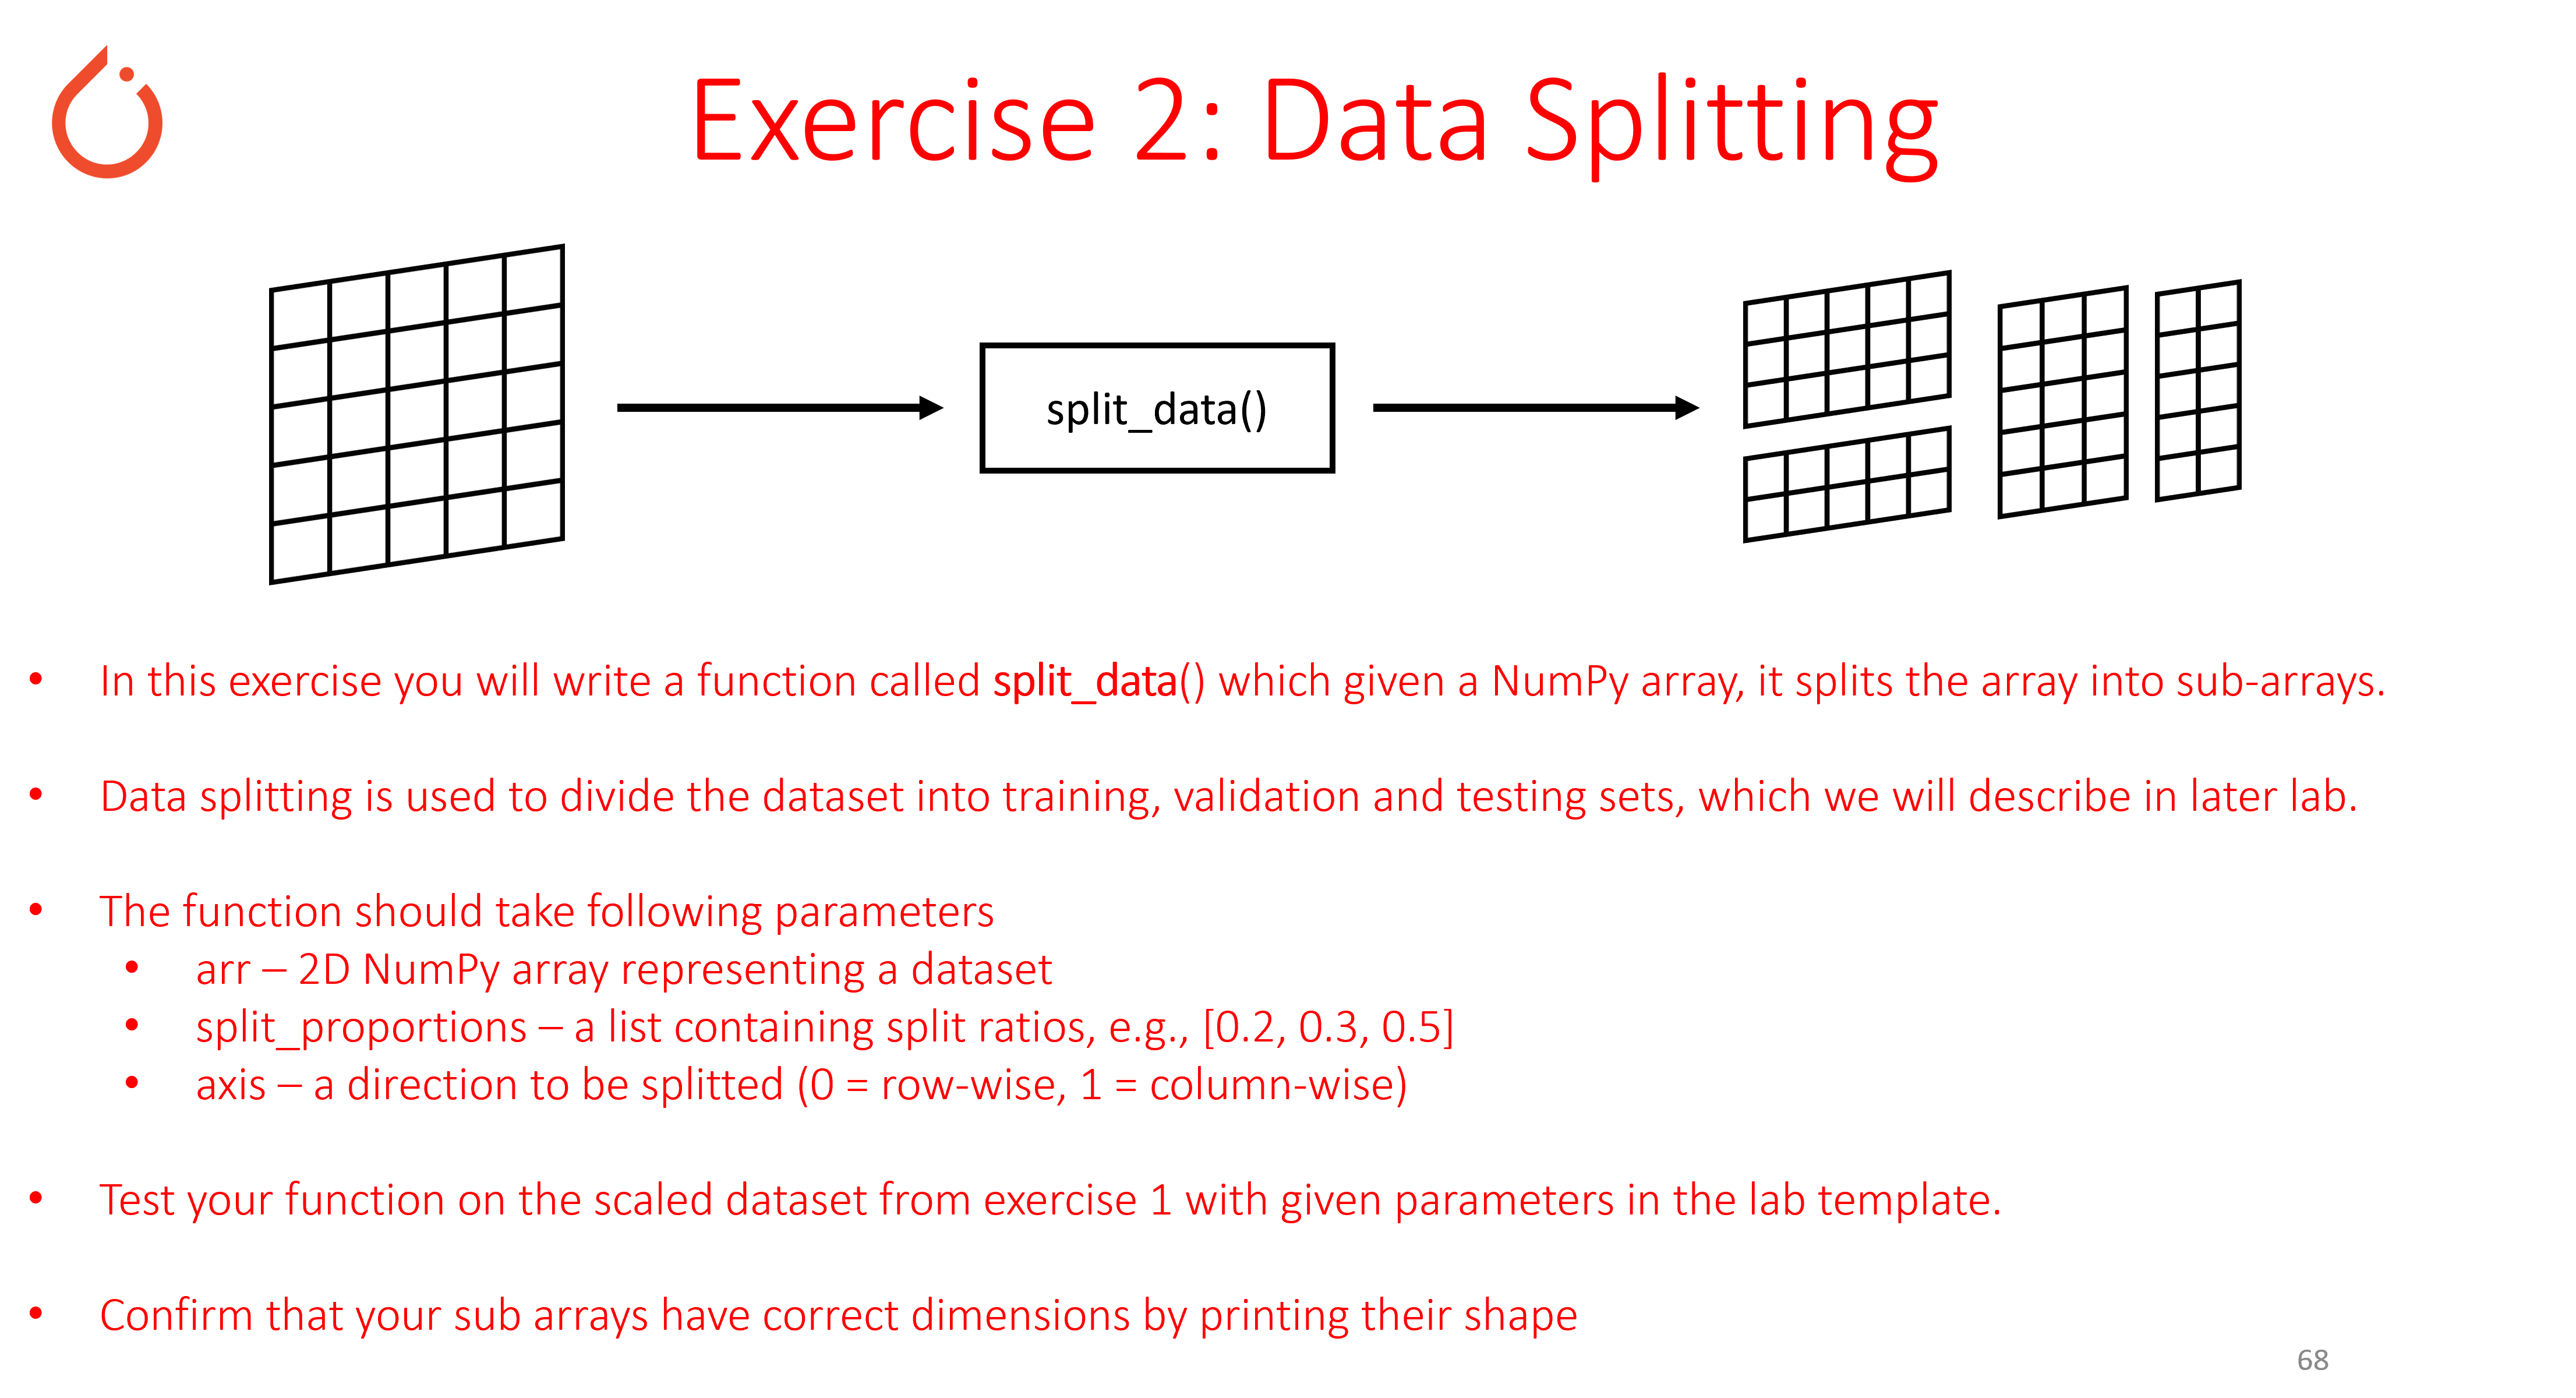

In [12]:
Image('lab1_exercise2.png', width = 1000)

## Task 2.1: Create the Splitting Function

In [13]:
# Create the splitting function

def split_data(arr, split_proportions, axis):
    
    # Returns a list of numpy sub-arrays according to split proportions
    
    # Step 1: number of rows (axis = 0) or columns (axis = 1) in arr
    n = arr.shape[axis]
    
    # Step 2: running total of the proportions, e.g. [0.6, 0.2, 0.2] -> [0.6, 0.8, 1.0]
    cumulative = np.cumsum(split_proportions)
    
    # Step 3: positions where the array is cut, e.g. [0.6, 0.8] x 420 -> [252, 336]
    split_indices = np.round(cumulative[:-1] * n).astype(int)
    
    # Step 4: cut the array at those positions
    split_data_list = np.split(arr, split_indices, axis = axis)
    
    return split_data_list

## Task 2.2: Test the Splitting Function

In [14]:
# Test your split function against scaled CMS Calorimeter dataset from Part 1

sub_data_list_1 = split_data(arr = CMS_calori_dataset_np_sub_scaled, 
                                    split_proportions = [0.6, 0.2, 0.2], axis = 0)

In [15]:
# Confirm that dataset has been split into correct shapes
# The correct dimensions should be (252, 6) (84, 6) (84, 6)

print(sub_data_list_1[0].shape, sub_data_list_1[1].shape, sub_data_list_1[2].shape)

(252, 6) (84, 6) (84, 6)


In [16]:
# Test your split function against scaled CMS Calorimeter dataset from Part 1

sub_data_list_2 = split_data(arr = CMS_calori_dataset_np_sub_scaled, 
                                                split_proportions = [0.5, 0.5], axis = 1)

In [17]:
# Confirm that dataset has been split into correct shapes
# The correct dimensions should be (420, 3) (420, 3)

print(sub_data_list_2[0].shape, sub_data_list_2[1].shape)

(420, 3) (420, 3)


## Task 2.3: Prepare Data - Iris Dataset

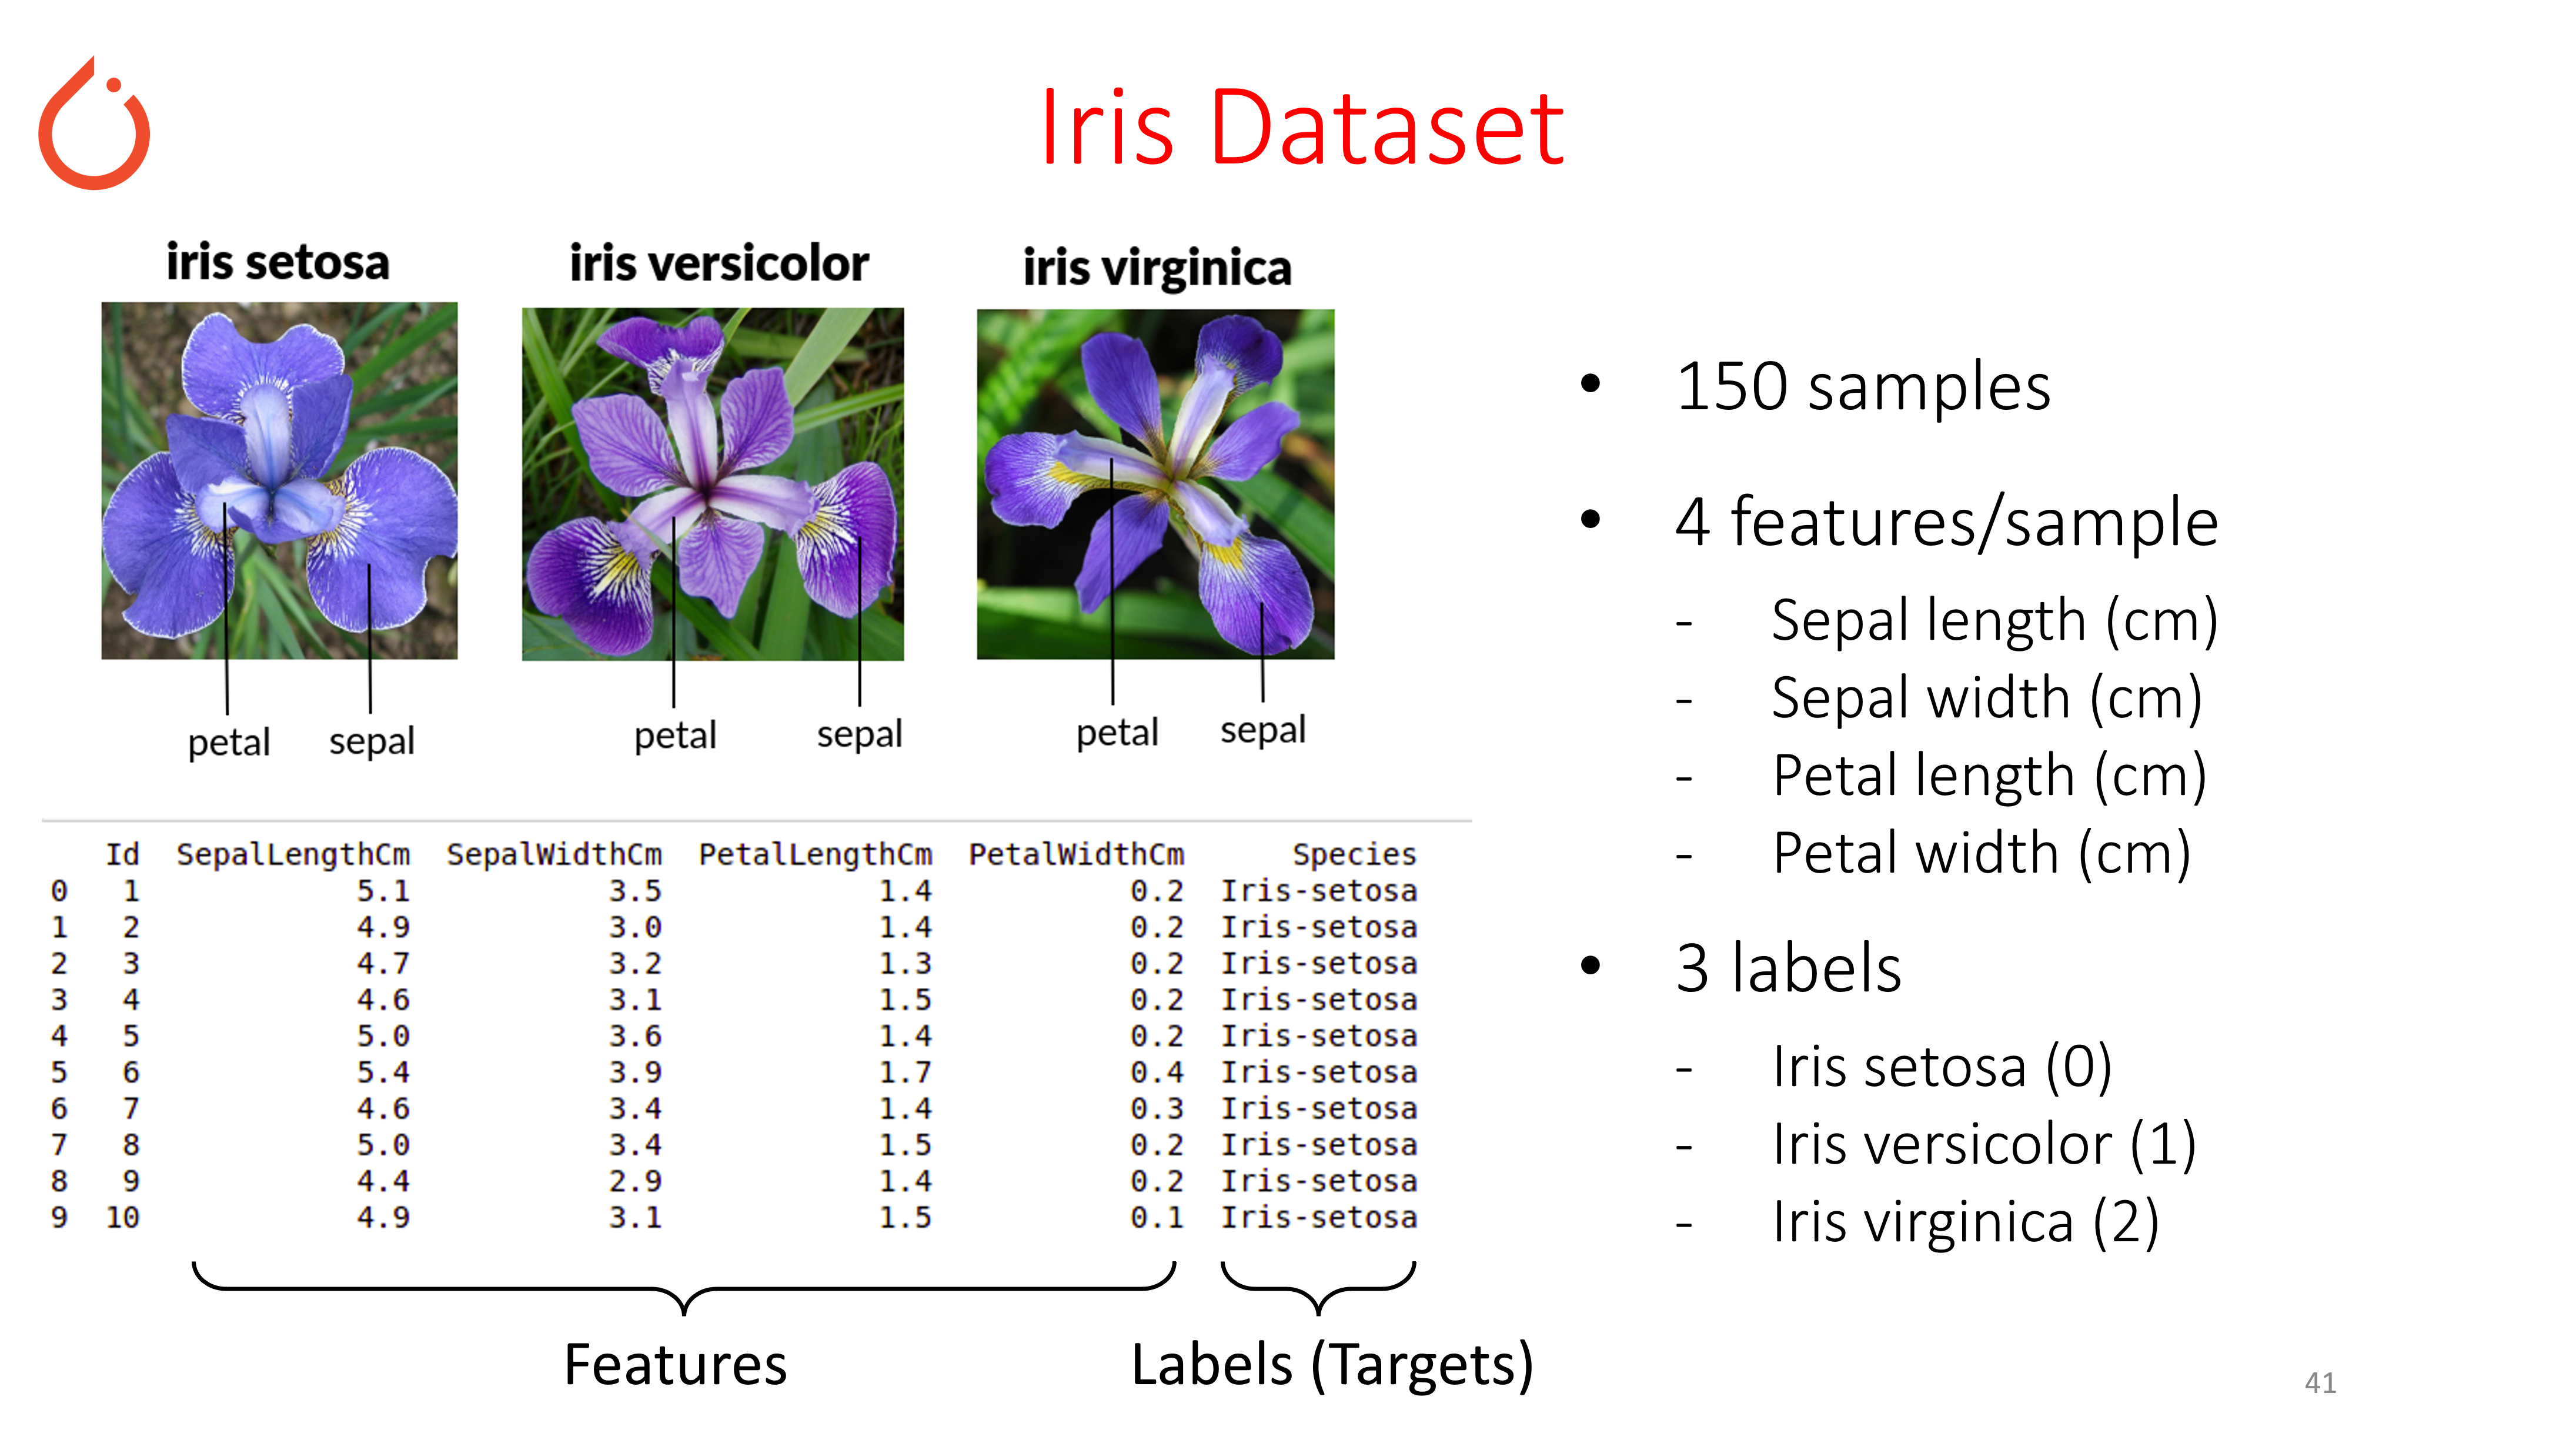

In [18]:
Image('iris_dataset.png', width = 1000)

In [19]:
from sklearn.datasets import load_iris

# iris dataset is available from scikit-learn package
iris = load_iris()

# Load the X (features) and y (targets) for training
X_train = iris['data']
y_train = iris['target']

# Load the name labels for features and targets
feature_names = iris['feature_names']
names = iris['target_names']

In [20]:
# Print the first 10 training samples for both features and targets

print(X_train[:10, :], y_train[:10]) 

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]] [0 0 0 0 0 0 0 0 0 0]


In [21]:
# Print the dimensions of features and targets

print(X_train.shape, y_train.shape)

(150, 4) (150,)


In [22]:
# feature_names contains name for each column in X_train
# For targets, 0 -> setosa, 1 -> versicolor, 2 -> virginica

print(feature_names, names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] ['setosa' 'versicolor' 'virginica']


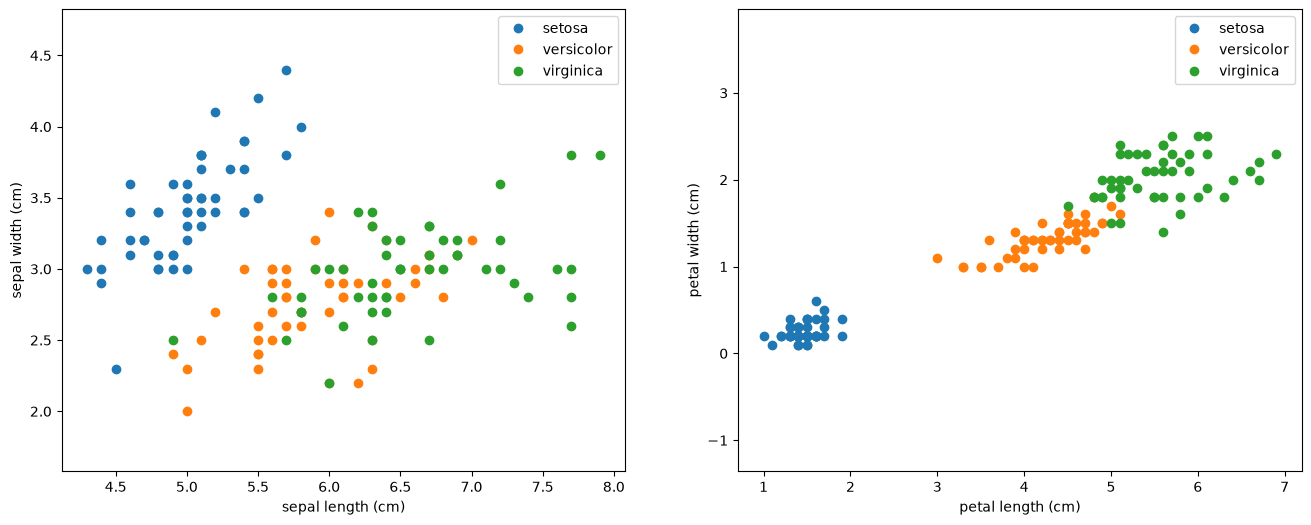

In [23]:
# We can visualize the dataset before training

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# enumerate picks up both the index (0, 1, 2) and the element ('setosa', 'versicolor', 'virginica') from "names"
# loop 1: target = 0, target_name = 'setosa'
# loop 2: target = 1, target_name = 'versicolor' etc

for target, target_name in enumerate(names):
    
    # Subset the rows of X_train that fall into each flower category using boolean mapping
    X_plot = X_train[y_train == target]
    
    # Plot the sepal length versus sepal width for the flower category
    ax1.plot(X_plot[:, 0], X_plot[:, 1], linestyle='none', marker='o', label=target_name)

# Label the plot
ax1.set_xlabel(feature_names[0])
ax1.set_ylabel(feature_names[1])
ax1.axis('equal')
ax1.legend()

# Repeat the above process but with petal length versus petal width. We see a stronger correlation here
# and better differentiation between flowers, indicating this will be a stronger signal for training.
# The differentiation is strong enough that you could probably train the entire model on the petal width
# and length without much if any loss of accuracy, and it would be a less expensive model.
for target, target_name in enumerate(names):
    
    X_plot = X_train[y_train == target]
    
    ax2.plot(X_plot[:, 2], X_plot[:, 3], linestyle='none', marker='o', label=target_name)
    
ax2.set_xlabel(feature_names[2])
ax2.set_ylabel(feature_names[3])
ax2.axis('equal')
ax2.legend()

## Task 2.4: Scale the Iris Features

In [24]:
# Perform standard scaling on the Iris features using your scale_data() function from Part 1
# Scaled data makes it easier for the model in Part 3 to learn

X_train = scale_data(X_train)

# Check: every column should now have mean = 0 and standard deviation = 1, and they do.
print('Mean of each column:', np.round(X_train.mean(axis = 0), 3))
print('Std of each column: ', np.round(X_train.std(axis = 0), 3))

Mean of each column: [-0. -0. -0. -0.]
Std of each column:  [1. 1. 1. 1.]


---
# Part 3: Iris Classification using Regression - Fit Your First Model (~50 min)

| Task | Description | Time |
|---|---|---|
| 3.1 | Define the model | ~10 min |
| 3.2 | Define the hyperparameters | ~5 min |
| 3.3 | Identify the tracked values | ~5 min |
| 3.4 | Train the model | ~15 min |
| 3.5 | Visualize and evaluate the model (goal: training accuracy >90% under 50 epochs) | ~15 min |
| Bonus | Optional challenges | optional |

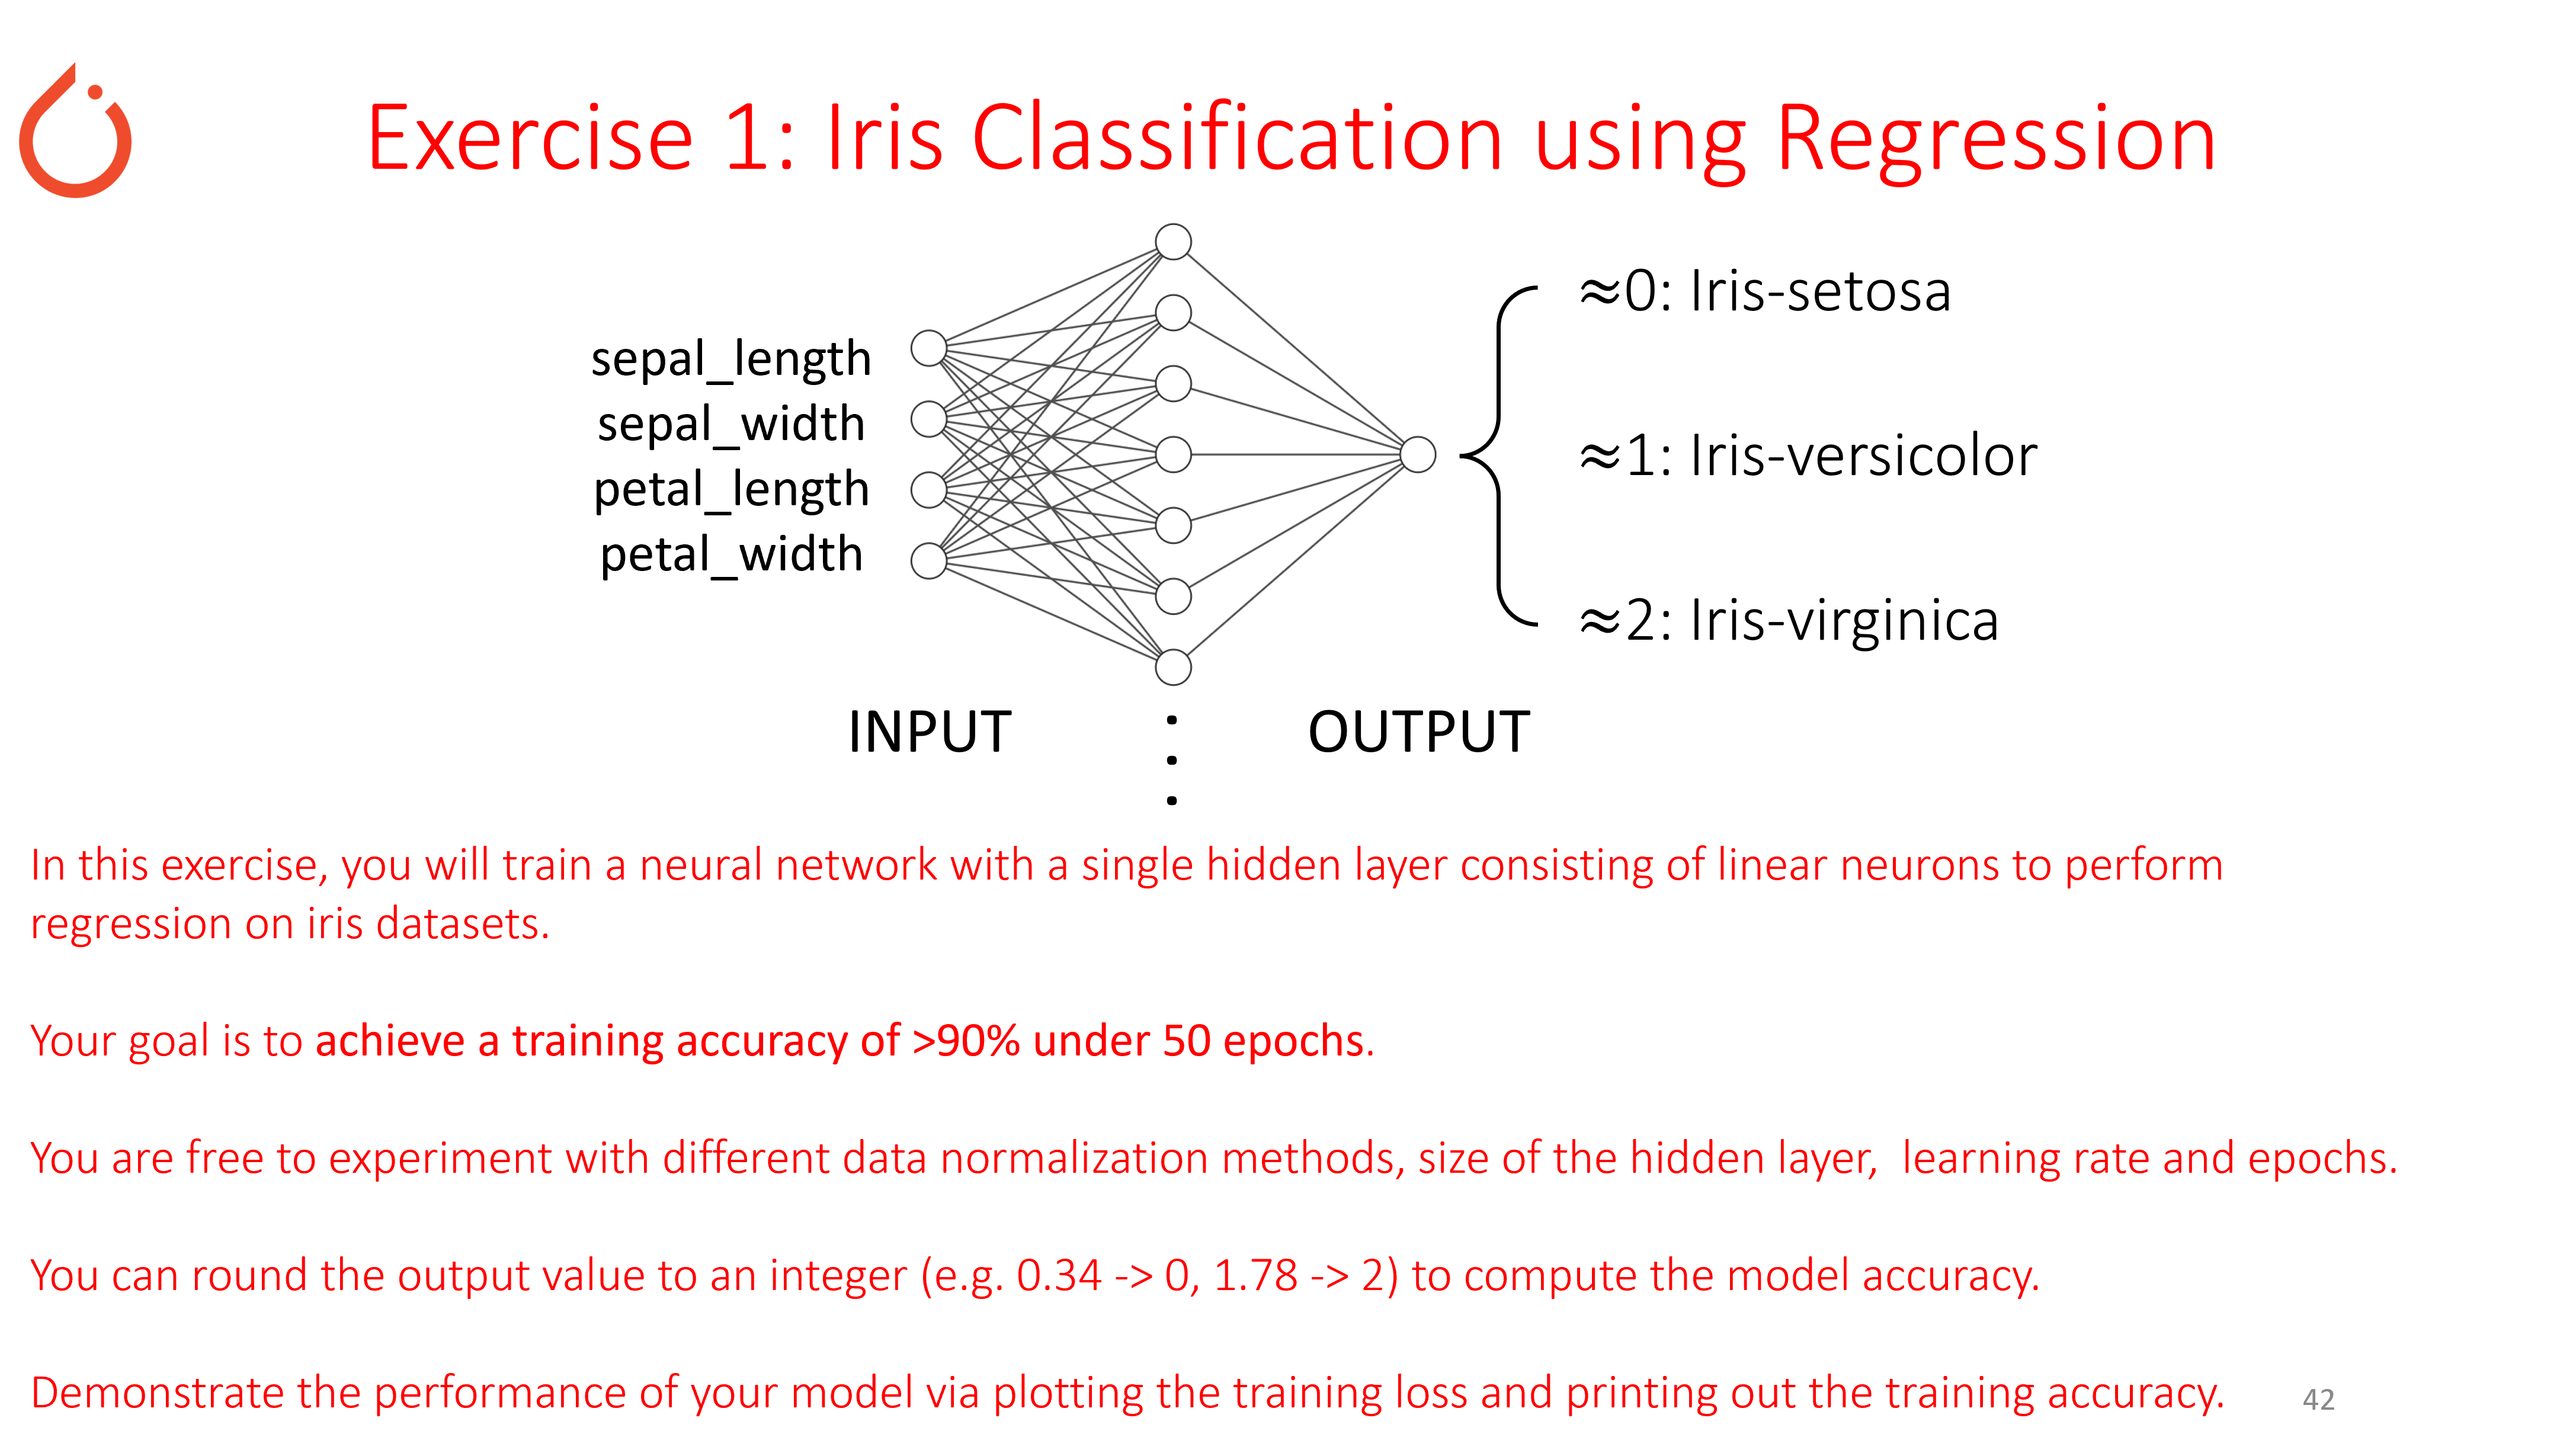

In [25]:
Image('lab2_exercise1.png', width = 1000)

## Task 3.1: Define Model

In [26]:
# A neural network with a single hidden layer of linear neurons. I added number of neurons as an optional input.
#   layer1: input (4 features) -> hidden layer (X neurons)
#   layer2: hidden layer (X neurons) -> output (1 number)

class irisClassification(torch.nn.Module):
    
    def __init__(self, input_dim, output_dim, num_neurons=10):
        
        super(irisClassification, self).__init__()
        
        self.layer1 = torch.nn.Linear(input_dim, num_neurons)

        self.layer2 = torch.nn.Linear(num_neurons, output_dim)
        
    def forward(self, x):
        
        out = self.layer1(x)
        out = self.layer2(out)
        
        return out

## Task 3.2: Define Hyperparameters

In [27]:
# Hint: number of features per flower (4). Again, I think we could probably train this model on 2 features.
input_dim = 4

# Hint: the model outputs a single number (1), which indicates the type of flower.
output_dim = 1

# Set seed so that the results do not fluctuate due to changing initial weights.
torch.manual_seed(0)
model = irisClassification(input_dim, output_dim, num_neurons=10)

# Set the learning rate.
learning_rate = 0.1

# Set the number of epochs.
epochs  = 45

# We will use gradient descent for our optimizer and Mean Squared Error Loss function
loss_func = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)

## Task 3.3: Identify Tracked Values

In [28]:
# follow models performance over each epoch. Identify a metric and track it over epochs
# Here we track the training loss and training accuracy over epochs.

train_loss_list = []
train_accuracy_list = []

## Task 3.4: Train Model

In [29]:
X_train = torch.from_numpy(X_train).float()
y_train = torch.from_numpy(y_train).float()

for epoch in range(epochs):
    
    # Step 1: make predictions. squeeze() turns the shape (150, 1) into (150,) to match y_train
    outputs = model(X_train).squeeze()
    
    # Step 2: compute the loss between the predictions and the targets
    loss = loss_func(outputs, y_train)
    
    # Step 3: reset the gradients
    optimizer.zero_grad()
    
    # Step 4: compute the gradients
    loss.backward()
    
    # Step 5: update the model weights
    optimizer.step()
    
    # Step 6: save the loss of this epoch in the list
    train_loss_list.append(loss.item())

    # Step 7: compute and save the training accuracy
    # at each epoch in a list (code from 3.5)
    with torch.no_grad():
        y_pred = model(X_train).squeeze()
        y_pred_rounded = torch.round(y_pred)
        correct = (y_pred_rounded == y_train).sum().item()
        accuracy = correct / len(y_train)
        train_accuracy_list.append(accuracy)
    
    print('Epoch:', epoch, 'Loss:', loss.item(), 'Accuracy:', accuracy)

Epoch: 0 Loss: 1.885718584060669 Accuracy: 0.5733333333333334
Epoch: 1 Loss: 0.39369451999664307 Accuracy: 0.8
Epoch: 2 Loss: 0.16686446964740753 Accuracy: 0.8733333333333333
Epoch: 3 Loss: 0.10702154785394669 Accuracy: 0.9
Epoch: 4 Loss: 0.08549026399850845 Accuracy: 0.9066666666666666
Epoch: 5 Loss: 0.07622641324996948 Accuracy: 0.9133333333333333
Epoch: 6 Loss: 0.07144766300916672 Accuracy: 0.9333333333333333
Epoch: 7 Loss: 0.06844961643218994 Accuracy: 0.94
Epoch: 8 Loss: 0.06624668836593628 Accuracy: 0.9333333333333333
Epoch: 9 Loss: 0.06445695459842682 Accuracy: 0.94
Epoch: 10 Loss: 0.06291868537664413 Accuracy: 0.9533333333333334
Epoch: 11 Loss: 0.061555638909339905 Accuracy: 0.96
Epoch: 12 Loss: 0.0603274330496788 Accuracy: 0.9666666666666667
Epoch: 13 Loss: 0.05921018496155739 Accuracy: 0.9666666666666667
Epoch: 14 Loss: 0.058188240975141525 Accuracy: 0.9666666666666667
Epoch: 15 Loss: 0.05725043639540672 Accuracy: 0.9666666666666667
Epoch: 16 Loss: 0.056388162076473236 Accura

## Task 3.5: Visualize and Evaluate Model

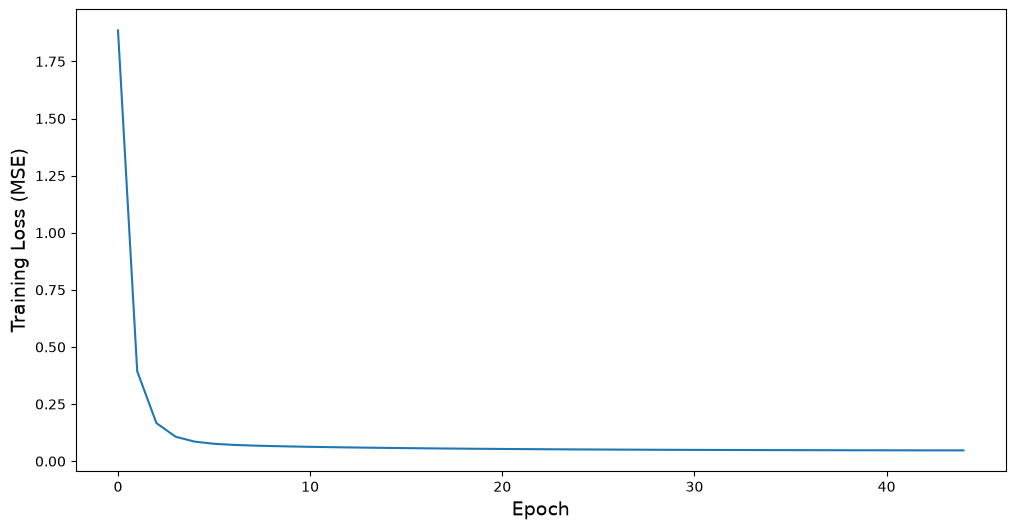

In [30]:
# Plot your training loss throughout the training
# Include proper x and y labels for the plot

plt.figure(figsize=(12, 6))

plt.plot(train_loss_list)
plt.xlabel('Epoch', fontsize = 14)
plt.ylabel('Training Loss (MSE)', fontsize = 14)

plt.show()

In [31]:
# Confirm that your model's training accuracy is >90%

with torch.no_grad():
    
    # Compare your model predictions with targets (y_train) to compute the training accuracy     
    y_pred = model(X_train).squeeze()
        
# Training accuracy = (# of correct predictions) / (total # of training samples)
# You can round the model predictions to integer (e.g. 0.34 -> 0, 1.78 -> 2)

y_pred_rounded = torch.round(y_pred)

correct = (y_pred_rounded == y_train).sum().item()     # Done for you: number of correct predictions

# Accuracy is the total number of correct predictions over the total number of predictions.
accuracy = correct / len(y_train)

print('Training accuracy:', accuracy * 100, '%')

Training accuracy: 97.33333333333334 %


---
# Bonus (Optional)

These challenges are **not required**. They are for students who finish early and want an extra challenge.

### Bonus 1: Experiment with the Model Settings

You are free to experiment with different data normalization methods, size of the hidden layer, learning rate and epochs. Can you still reach a training accuracy of >90% under 50 epochs?

Ideas to try:
* Skip Task 2.4 (train on the **unscaled** Iris features). What happens to the loss with the same learning rate?
* Change the hidden layer size (the `10` in Task 3.1).
* Change `learning_rate` and `epochs` in Task 3.2. What is the smallest number of epochs that still gives >90%?

To try a new setting, change the value, then re-run the cells from **Task 2.3** onward (the data must be reloaded each time).

Record your results in the table below:

| Scaled data? | Hidden layer size | Learning rate | Epochs | Training accuracy |
|---|---|---|---|---|
| Yes | 10 | 0.1 | 45 | 97.3% |
| Yes | 100 | 0.1 | 45 | 0.0% |
| Yes | 50 | 0.1 | 45 | 96.7% |
| Yes | 5 | 0.1 | 45 | 96.0% |
| Yes | 2 | 0.1 | 45 | 97.3% |
| Yes | 1 | 0.1 | 45 | 97.3% |
| Yes | 10 | 0.01 | 45 | 89.3% |
| Yes | 100 | 0.01 | 45 | 96.0% |
| Yes | 10 | 0.1 | 20 | 96.7% |
| No | 10 | 0.1 | 45 | 0.0% |
| No | 10 | 0.01 | 45 | 96.7% |

The initial weights are randomly selected, and they impact the result by up to 3%, so this process is not deterministic. To get the same result each time, we'd need to ensure the random seed is constant so the initial weights do not change.

It turns out that this model performs equally well on the training set with a single neuron, likely because there is no nonlinearity between layers.

If the data is not scaled, the loss blows up unless the learning rate is decreased.

### Bonus 2: Track a Second Metric

In Task 3.3 we only tracked the training loss. Also track the **training accuracy** over the epochs, then plot it with proper x and y labels.

No hints for this one. You can reuse the code from Task 3.5 inside the training loop.

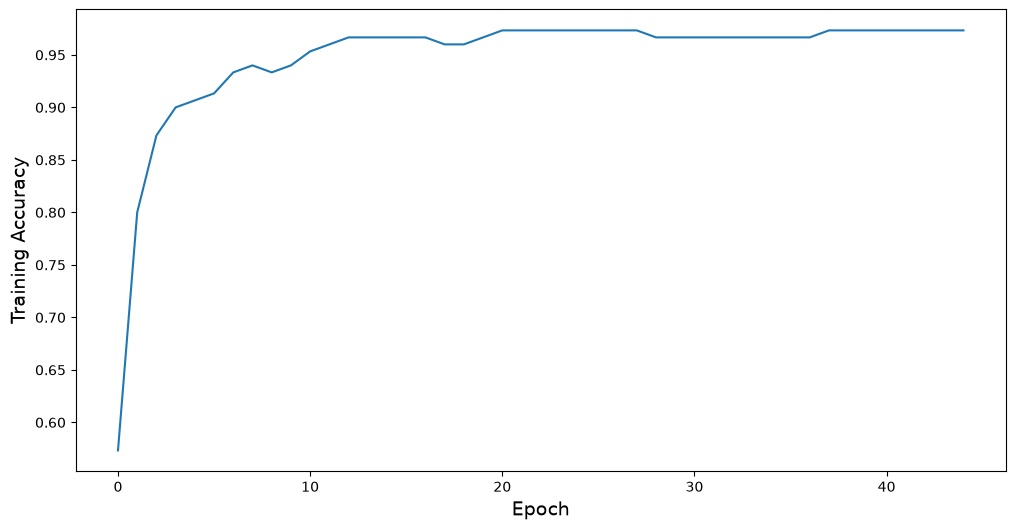

In [32]:
# Bonus 2: track and plot the training accuracy over epochs

plt.figure(figsize=(12, 6))

plt.plot(train_accuracy_list)
plt.xlabel('Epoch', fontsize = 14)
plt.ylabel('Training Accuracy', fontsize = 14)

plt.show()

# Interestingly, the training accuracy does not necessarily increase monotonically with epochs.